# 01 — Dataset EDA, Stratified Splitting & Preprocessing Pipeline

* **Goal:** Inspect the 25-class Food-101 subset, verify class balance and image integrity, create a deterministic stratified train/validation split while holding out the official test split, define and visualize the Albumentations + CutMix training pipeline, and benchmark DataLoader throughput.
* **Inputs:** `data/subset_classes.json`, Food-101 dataset under `data/raw/food-101/` (downloaded via `python data/download_food101.py`).
* **Outputs:** `data/splits.json`, `models/class_names.json`, `notebooks/_shared/dataloader_config.json`.
* **Expected Runtime:** ~2–4 min on CPU or GPU (I/O bound).

In [1]:
from __future__ import annotations

import json
import os
import random
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import DataLoader
from torchvision.transforms import v2 as Tv2

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)
sns.set_theme(style="whitegrid")

In [2]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from _shared.paths import DATA, MODELS, RAW, ROOT
from _shared.datasets import Food25, class_names, get_subset_samples, load_rgb, write_class_names
from _shared.transforms import (
    IMAGENET_MEAN,
    IMAGENET_STD,
    build_eval_transform,
    build_single_aug,
    build_train_transform,
    denormalize,
    eval_numpy,
)

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
)
FAST_DEV = os.environ.get("FAST_DEV", "0") == "1"
print(f"Selected device: {DEVICE} | FAST_DEV={FAST_DEV} | ROOT={ROOT}")

Selected device: cpu | FAST_DEV=True | ROOT=C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine


## 1. Load the 25-Class Food-101 Subset

We load the official Food-101 `train` and `test` splits filtered to our 25 target classes (`data/subset_classes.json`). Maintaining a single canonical class list ensures that class index $k \in \{0, \dots, 24\}$ means the exact same dish across training, ONNX export, nutrition lookup, and the FastAPI backend.

In [3]:
CLASSES = class_names()
assert len(CLASSES) == 25, f"Expected 25 classes, got {len(CLASSES)}"

train_samples = get_subset_samples("train")
test_samples = get_subset_samples("test")

rows = [
    {"path": p, "label": lbl, "class_name": CLASSES[lbl], "split": "train"}
    for p, lbl in train_samples
] + [
    {"path": p, "label": lbl, "class_name": CLASSES[lbl], "split": "test"}
    for p, lbl in test_samples
]
df = pd.DataFrame(rows)
print(f"Total subset images: {len(df):,} (train={len(train_samples):,}, test={len(test_samples):,})")
df.head()

Total subset images: 750 (train=500, test=250)


,path,label,class_name,split
0,C:\Skills\Projects\Visual Meal Recognition & M...,1,caesar_salad,train
1,C:\Skills\Projects\Visual Meal Recognition & M...,1,caesar_salad,train
2,C:\Skills\Projects\Visual Meal Recognition & M...,1,caesar_salad,train
3,C:\Skills\Projects\Visual Meal Recognition & M...,1,caesar_salad,train
4,C:\Skills\Projects\Visual Meal Recognition & M...,1,caesar_salad,train


## 2. Class Distribution, Image Geometry & Channel Statistics

Before training a vision backbone, we verify three things:
1. **Class balance:** Every class should have identical support (750 train / 250 test in full Food-101) so macro-F1 and accuracy are not skewed by prior shift.
2. **Geometry & file integrity:** Unreadable files or extreme aspect ratios can crash DataLoader workers mid-epoch or suffer severe distortion under cropping.
3. **Channel statistics:** We compare empirical RGB mean/std on a random sample against the ImageNet normalization constants
$$\mu_{\text{ImageNet}} = [0.485,\; 0.456,\; 0.406], \qquad \sigma_{\text{ImageNet}} = [0.229,\; 0.224,\; 0.225]$$
Because our MobileNetV3-Large backbone was pretrained on ImageNet-1K with these exact moments, preserving $\mu_{\text{ImageNet}}, \sigma_{\text{ImageNet}}$ keeps early convolutional filters in their calibrated operating regime.

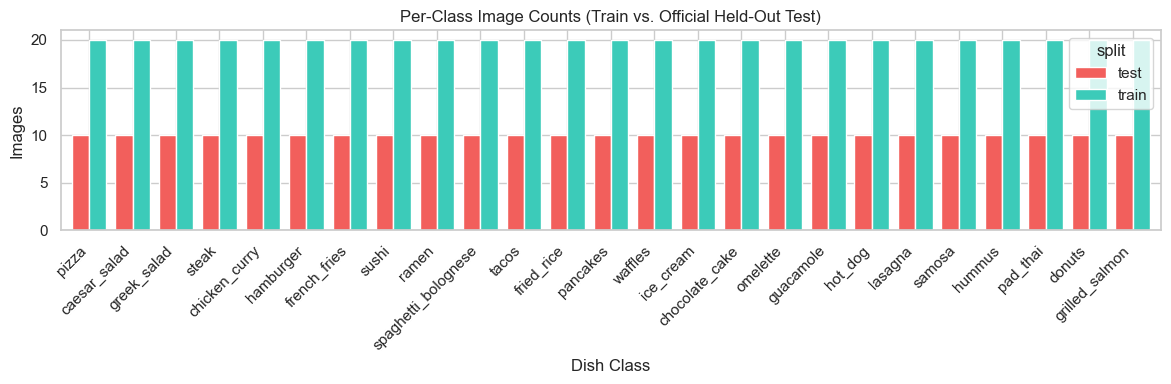

In [4]:
counts = df.groupby(["class_name", "split"]).size().unstack(fill_value=0).loc[CLASSES]
expected_train = counts["train"].iloc[0]
expected_test = counts["test"].iloc[0]
assert (counts["train"] == expected_train).all(), "Train split is not balanced across classes!"
assert (counts["test"] == expected_test).all(), "Test split is not balanced across classes!"

fig, ax = plt.subplots(figsize=(12, 4))
counts.plot(kind="bar", ax=ax, width=0.8, color=["#F25F5C", "#3CCBB9"])
ax.set_title("Per-Class Image Counts (Train vs. Official Held-Out Test)")
ax.set_ylabel("Images")
ax.set_xlabel("Dish Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Checked 200 images — 0 corrupted files.
Width  : median=280px, min=280px, max=280px
Height : median=260px, min=260px, max=260px
Aspect : mean=1.08, p05=1.08, p95=1.08
Empirical RGB mean: [0.453, 0.473, 0.469] vs ImageNet [0.485, 0.456, 0.406]
Empirical RGB std : [0.306, 0.31, 0.307] vs ImageNet [0.229, 0.224, 0.225]


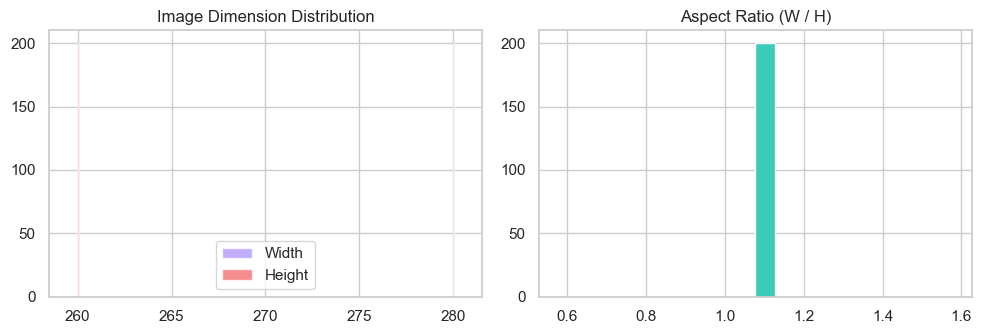

In [5]:
sample_n = min(len(df), 200 if FAST_DEV else 2000)
sample_df = df.sample(n=sample_n, random_state=SEED)

widths, heights, ratios = [], [], []
corrupted = []
channel_sum = np.zeros(3, dtype=np.float64)
channel_sq_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0

for p in sample_df["path"]:
    try:
        with Image.open(p) as im:
            im_rgb = im.convert("RGB")
            w, h = im_rgb.size
            arr = np.asarray(im_rgb, dtype=np.float32) / 255.0
        widths.append(w)
        heights.append(h)
        ratios.append(w / max(h, 1))
        channel_sum += arr.reshape(-1, 3).sum(axis=0)
        channel_sq_sum += (arr.reshape(-1, 3) ** 2).sum(axis=0)
        pixel_count += arr.shape[0] * arr.shape[1]
    except Exception as exc:
        corrupted.append((p, str(exc)))

assert len(corrupted) == 0, f"Found corrupted images: {corrupted[:5]}"
emp_mean = channel_sum / max(pixel_count, 1)
emp_std = np.sqrt(np.maximum(channel_sq_sum / max(pixel_count, 1) - emp_mean**2, 1e-8))

print(f"Checked {sample_n} images — 0 corrupted files.")
print(f"Width  : median={np.median(widths):.0f}px, min={np.min(widths)}px, max={np.max(widths)}px")
print(f"Height : median={np.median(heights):.0f}px, min={np.min(heights)}px, max={np.max(heights)}px")
print(f"Aspect : mean={np.mean(ratios):.2f}, p05={np.percentile(ratios, 5):.2f}, p95={np.percentile(ratios, 95):.2f}")
print(f"Empirical RGB mean: {np.round(emp_mean, 3).tolist()} vs ImageNet {list(IMAGENET_MEAN)}")
print(f"Empirical RGB std : {np.round(emp_std, 3).tolist()} vs ImageNet {list(IMAGENET_STD)}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(widths, bins=20, alpha=0.7, label="Width", color="#A78BFA")
axes[0].hist(heights, bins=20, alpha=0.7, label="Height", color="#F25F5C")
axes[0].set_title("Image Dimension Distribution")
axes[0].legend()
axes[1].hist(ratios, bins=20, color="#3CCBB9")
axes[1].set_title("Aspect Ratio (W / H)")
plt.tight_layout()
plt.show()

## 3. Stratified Train / Validation Split

We split the official training set into **90% train** and **10% validation** using `StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)`. The official Food-101 test split remains completely untouched until the single final evaluation at the end of Notebook 02.

In [6]:
labels_np = np.array([lbl for _, lbl in train_samples], dtype=np.int64)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
train_idx, val_idx = next(sss.split(np.zeros(len(labels_np)), labels_np))

expected_val_per_class = len(val_idx) / len(CLASSES)
val_class_counts = np.bincount(labels_np[val_idx], minlength=len(CLASSES))
assert np.all(np.abs(val_class_counts - expected_val_per_class) <= 1.0), (
    f"Stratification failed: counts={val_class_counts}"
)

splits_payload = {
    "seed": SEED,
    "val_fraction": 0.1,
    "train_indices": [int(i) for i in train_idx],
    "val_indices": [int(i) for i in val_idx],
    "num_train": int(len(train_idx)),
    "num_val": int(len(val_idx)),
    "num_test": int(len(test_samples)),
}
splits_path = DATA / "splits.json"
splits_path.write_text(json.dumps(splits_payload, indent=2) + "\n", encoding="utf-8")
class_names_path = write_class_names()
print(f"Saved stratified splits -> {splits_path} (train={len(train_idx)}, val={len(val_idx)}, test={len(test_samples)})")
print(f"Saved class names       -> {class_names_path}")

Saved stratified splits -> C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine\data\splits.json (train=450, val=50, test=250)
Saved class names       -> C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine\models\class_names.json


## 4. Augmentation Pipeline & CutMix

Meal photos in the wild vary in lighting, camera tilt, zoom, and partial occlusion. Our training pipeline in `_shared/transforms.py` applies:
1. `LongestMaxSize(256)` $\rightarrow$ `RandomResizedCrop(224, scale=(0.6, 1.0), ratio=(0.75, 1.33))`
2. `HorizontalFlip(p=0.5)` and `Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-15, 15), p=0.7)`
3. `ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05, p=0.8)` and `CoarseDropout(p=0.2)`
4. `Normalize(ImageNet)` $\rightarrow$ `ToTensorV2`

For **evaluation and production**, we use the deterministic contract (`_shared/transforms.py::eval_numpy`):
`Resize(shorter_side=256, INTER_LINEAR)` $\rightarrow$ `CenterCrop(224)` $\rightarrow$ `/255.0` $\rightarrow$ `Normalize(ImageNet)` $\rightarrow$ `CHW float32`.

At the batch level we apply **CutMix** with probability $p=0.5$ (`torchvision.transforms.v2.CutMix(num_classes=25, alpha=1.0)`):
$$\tilde{x} = M \odot x_A + (1-M)\odot x_B,\qquad \tilde{y} = \lambda y_A + (1-\lambda) y_B,\qquad \lambda \sim \mathrm{Beta}(\alpha,\alpha),\quad \lambda \approx 1 - \frac{\text{area}(B)}{H W}$$

C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine\.venv\Lib\site-packages\albumentations\__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.21). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine\notebooks\_shared\transforms.py:66: UserWarning: Argument 'fill' is not valid and will be ignored.
  A.CoarseDropout(


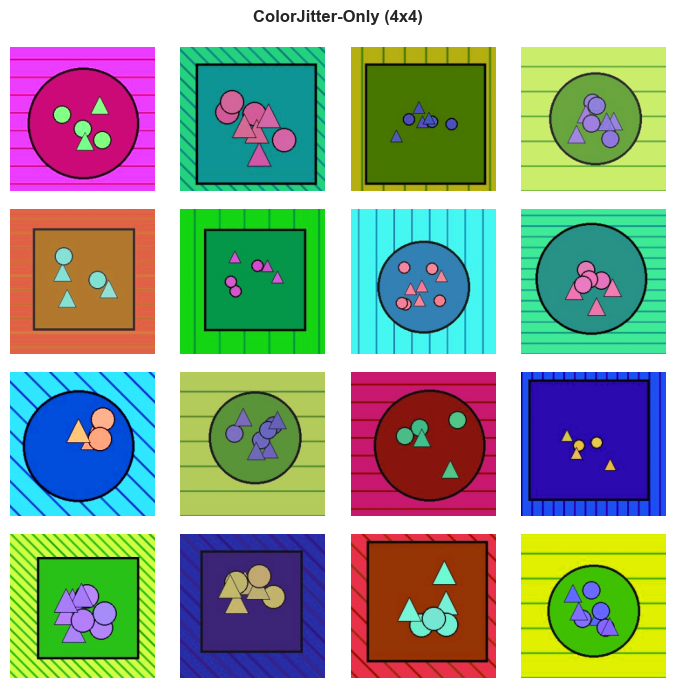

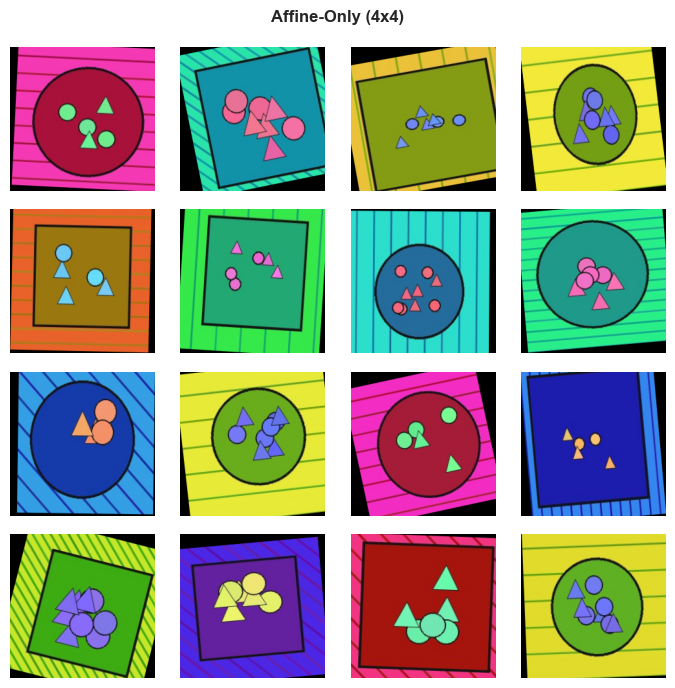

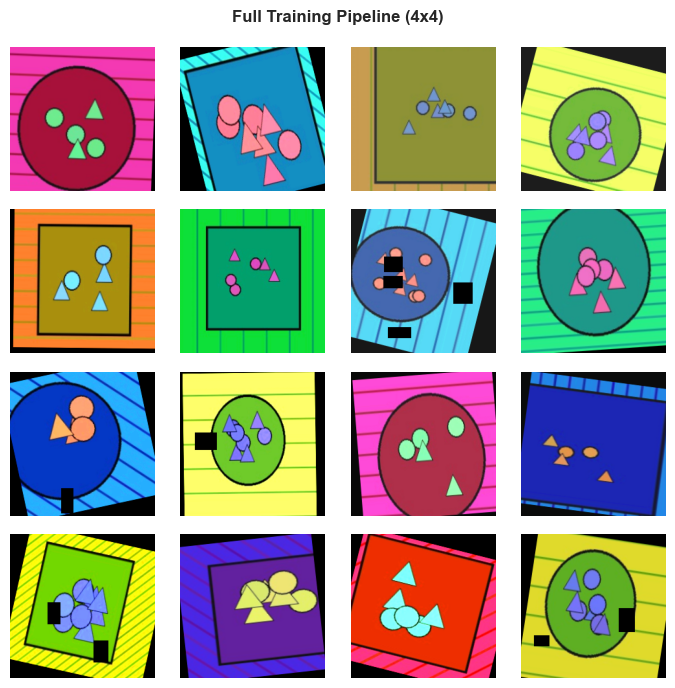

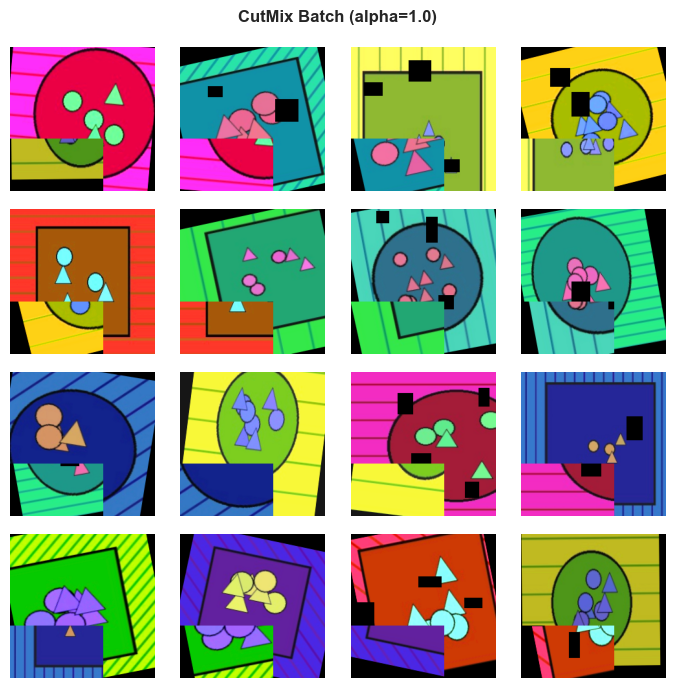

In [7]:
train_tf = build_train_transform()
eval_tf = build_eval_transform()
cj_tf = build_single_aug("colorjitter")
aff_tf = build_single_aug("affine")
cutmix = Tv2.CutMix(num_classes=len(CLASSES), alpha=1.0)


def show_grid(images: list[np.ndarray], title: str) -> None:
    fig, axes = plt.subplots(4, 4, figsize=(7, 7))
    fig.suptitle(title, fontsize=12, fontweight="bold")
    for ax, img in zip(axes.flat, images[:16]):
        ax.imshow(img)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


raw_imgs = [load_rgb(train_samples[i][0]) for i in train_idx[:16]]
show_grid([cj_tf(image=im)["image"] for im in raw_imgs], "ColorJitter-Only (4x4)")
show_grid([aff_tf(image=im)["image"] for im in raw_imgs], "Affine-Only (4x4)")
show_grid([denormalize(train_tf(image=im)["image"]) for im in raw_imgs], "Full Training Pipeline (4x4)")

batch_ds = Food25(train_samples, transform=train_tf, indices=train_idx[:16])
bx = torch.stack([batch_ds[i][0] for i in range(16)])
by = torch.tensor([batch_ds[i][1] for i in range(16)], dtype=torch.long)
cm_x, cm_y = cutmix(bx, by)
show_grid([denormalize(t) for t in cm_x], "CutMix Batch (alpha=1.0)")

## 5. DataLoader Throughput Benchmark

We benchmark `num_workers` $\in \{0, 2, 4\}$ to select the fastest worker configuration for this machine and record the choice in `notebooks/_shared/dataloader_config.json`.

In [8]:
bench_n = min(len(train_idx), 64 if FAST_DEV else 256)
bench_ds = Food25(train_samples, transform=train_tf, indices=train_idx[:bench_n])
worker_Candidates = [0] if (os.name == "nt" and FAST_DEV) else [0, 2, 4]
throughput: dict[int, float] = {}

for nw in worker_Candidates:
    try:
        loader = DataLoader(bench_ds, batch_size=32, shuffle=False, num_workers=nw)
        t0 = time.perf_counter()
        seen = 0
        for xb, _ in loader:
            seen += int(xb.size(0))
        dt = max(time.perf_counter() - t0, 1e-6)
        throughput[nw] = round(seen / dt, 1)
    except Exception as exc:
        print(f"num_workers={nw} unavailable ({exc}); skipping")

best_nw = max(throughput, key=throughput.get)
cfg_note = Path(ROOT / "notebooks" / "_shared" / "dataloader_config.json")
cfg_note.write_text(
    json.dumps({"best_num_workers": best_nw, "throughput_imgs_per_sec": throughput}, indent=2) + "\n",
    encoding="utf-8",
)
print(f"Throughput (imgs/sec): {throughput} -> selected num_workers={best_nw}")

Throughput (imgs/sec): {0: 51.4} -> selected num_workers=0
